In [51]:
import os, random, numpy as np
import torch, torchvision, torchvision.transforms as T, torch.nn as nn, torch.nn.functional as F
from torchvision.models import ResNet18_Weights, resnet18
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score

print(f"{torch.__version__=}")
print(f"{torchvision.__version__=}")

if torch.cuda.is_available(): 
    device = "cuda"
    print("cuda")
else:
    device = "cpu"
    print("cpu")

torch.__version__='2.14.1+cu130'
torchvision.__version__='0.29.1+cu130'
cuda


In [2]:
resnet18_model = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet18_model.to(device=device)

x = torch.randn((1, 3, 224, 224), device=device, dtype=torch.float32)
out = resnet18_model(x)
out.shape

torch.Size([1, 1000])

In [3]:
from PIL import Image

data_dir = "data/chest_xray"
test_dir = f"{data_dir}/test"
train_dir = f"{data_dir}/train"
val_dir = f"{data_dir}/val"
data = {}

for path in [test_dir, train_dir, val_dir]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = f"{path}/{cls}/"
        data[folder] = os.listdir(folder)
        print(f"{folder} : {len(data[folder])}")

# print(data)

data/chest_xray/test/NORMAL/ : 234
data/chest_xray/test/PNEUMONIA/ : 390
data/chest_xray/train/NORMAL/ : 1341
data/chest_xray/train/PNEUMONIA/ : 3875
data/chest_xray/val/NORMAL/ : 8
data/chest_xray/val/PNEUMONIA/ : 8


In [4]:
normal_imgs = data[f"{train_dir}/NORMAL/"][:3]
pneu_imgs = data[f"{train_dir}/PNEUMONIA/"][:3]

print("Normal Images:")
for img in normal_imgs:
    i = Image.open(f"{train_dir}/NORMAL/{img}")
    print(f"{img} : {i.size} , {i.mode}")

print("PNEUMONIA Images")
for img in pneu_imgs:
    i = Image.open(f"{train_dir}/PNEUMONIA/{img}")
    print(f"{img} : {i.size} , {i.mode}")

Normal Images:
IM-0300-0001.jpeg : (2020, 1565) , L
NORMAL2-IM-1277-0001-0002.jpeg : (1742, 1422) , L
IM-0261-0001.jpeg : (1596, 1330) , L
PNEUMONIA Images
person57_bacteria_270.jpeg : (1144, 832) , L
person654_bacteria_2546.jpeg : (1160, 824) , L
person705_virus_1303.jpeg : (1016, 816) , L


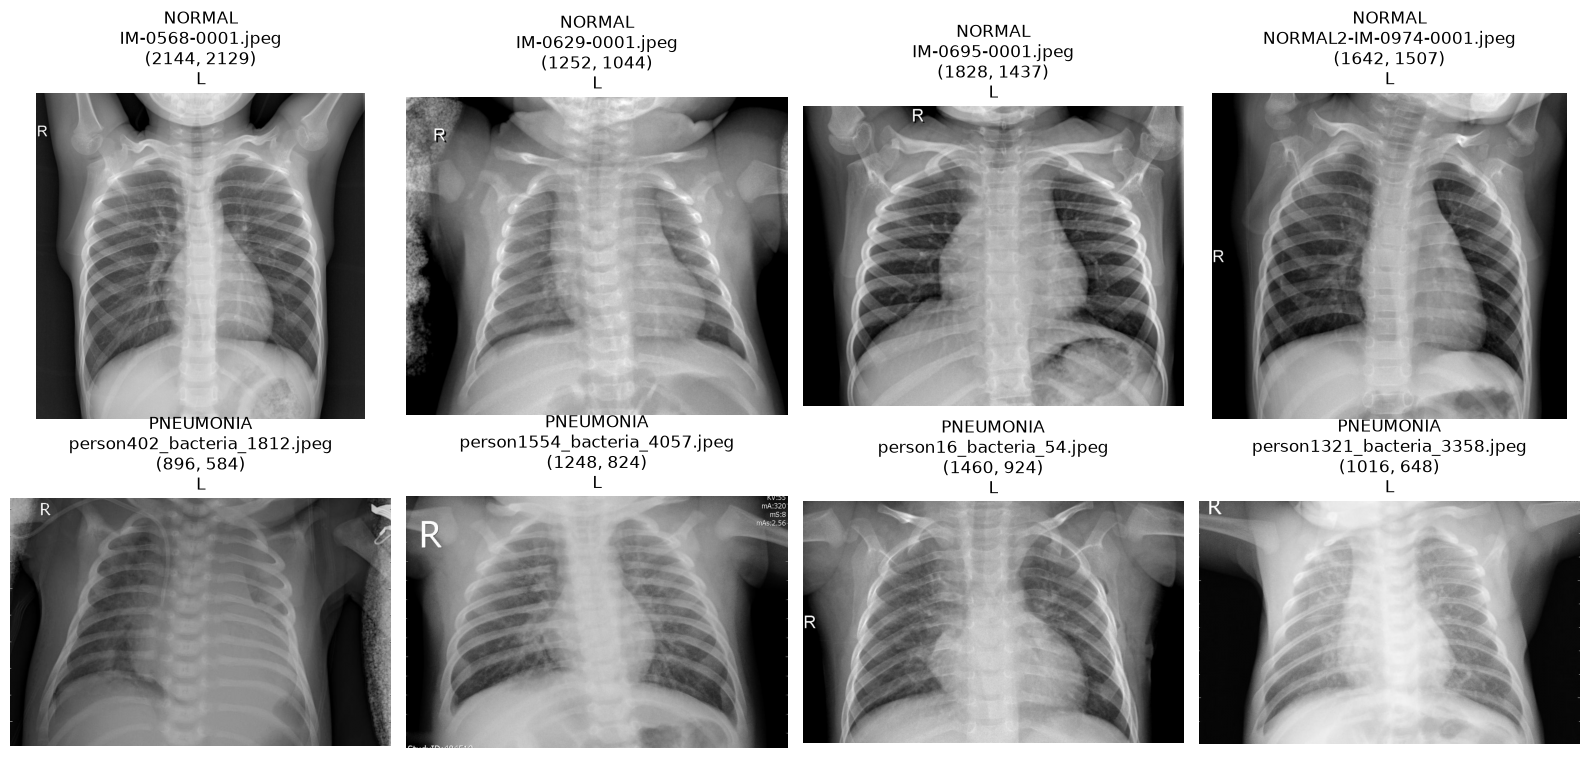

In [5]:

random.seed(3)
normal_imgs_grid = random.sample(data[f"{train_dir}/NORMAL/"], 4)
pneu_imgs_grid = random.sample(data[f"{train_dir}/PNEUMONIA/"], 4)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(len(normal_imgs_grid)):
    n_img, p_img = Image.open(f"{train_dir}/NORMAL/{normal_imgs_grid[i]}"), Image.open(f"{train_dir}/PNEUMONIA/{pneu_imgs_grid[i]}")
    axes[0, i].imshow(n_img, cmap="gray")
    axes[0, i].set_title(f"NORMAL\n{normal_imgs_grid[i]}\n{n_img.size}\n{n_img.mode}")
    axes[0, i].axis("off")
    axes[1, i].imshow(p_img, cmap="gray")
    axes[1, i].set_title(f"PNEUMONIA\n{pneu_imgs_grid[i]}\n{p_img.size}\n{p_img.mode}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

    

In [6]:
dimensions = {}
dimensions["normal"] = []
dimensions["pneumonia"] = []

for img in data[f"{data_dir}/train/NORMAL/"]:
    Img = Image.open(f"{train_dir}/NORMAL/{img}")
    dimensions["normal"].append(Img.size)

for img in data[f"{data_dir}/train/PNEUMONIA/"]:
    Img = Image.open(f"{train_dir}/PNEUMONIA/{img}")
    dimensions["pneumonia"].append(Img.size)

normal_dims = np.array(dimensions["normal"])
pneu_dims = np.array(dimensions["pneumonia"])

print(f"Normal\nmean dimenions = {normal_dims.mean(axis=0)}\nmedian dimensions = {np.median(normal_dims, axis=0)}\nAspect Ratio = {(normal_dims[:, 0] / normal_dims[:, 1]).mean()}\n")
print(f"Pneumonia\nmean dimenions = {pneu_dims.mean(axis=0)}\nmedian dimensions = {np.median(pneu_dims, axis=0)}\nAspect Ratio = {(pneu_dims[:, 0] / pneu_dims[:, 1]).mean()}\n")



Normal
mean dimenions = [1667.73452647 1381.43102163]
median dimensions = [1640. 1328.]
Aspect Ratio = 1.2277920511462639

Pneumonia
mean dimenions = [1200.4836129   825.02683871]
median dimensions = [1168.  776.]
Aspect Ratio = 1.513755093072343



In [7]:
def get_group(name, cls):
    if cls == "PNEUMONIA":
        return name.split("_")[0]          # person1554_bacteria_4057.jpeg -> person1554
    parts = name.split("-")
    i = parts.index("IM")
    return "-".join(parts[:i + 2])         # NORMAL2-IM-1277-0001-0002.jpeg -> NORMAL2-IM-1277

assert get_group("person1554_bacteria_4057.jpeg", "PNEUMONIA") == "person1554"
assert get_group("person23_bacteria_90.jpeg", "PNEUMONIA") == "person23"
assert get_group("IM-0300-0001.jpeg", "NORMAL") == "IM-0300"
assert get_group("NORMAL2-IM-1277-0001-0002.jpeg", "NORMAL") == "NORMAL2-IM-1277"

In [8]:
import pandas as pd

rows = []
for split in ["train", "val"]:            
    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = f"{data_dir}/{split}/{cls}"
        for name in sorted(os.listdir(folder)):
            if name.startswith("."):
                continue
            rows.append({
                "path": f"{folder}/{name}",
                "label": 1 if cls == "PNEUMONIA" else 0,
                "group": get_group(name, cls),
            })

df = pd.DataFrame(rows)

print(f"{len(df)=}")
print(df["label"].mean())
print(df.groupby("label")["group"].nunique())
df.head()

len(df)=5232
0.7421636085626911
label
0    1219
1    1642
Name: group, dtype: int64


,path,label,group
0,data/chest_xray/train/NORMAL/IM-0115-0001.jpeg,0,IM-0115
1,data/chest_xray/train/NORMAL/IM-0117-0001.jpeg,0,IM-0117
2,data/chest_xray/train/NORMAL/IM-0119-0001.jpeg,0,IM-0119
3,data/chest_xray/train/NORMAL/IM-0122-0001.jpeg,0,IM-0122
4,data/chest_xray/train/NORMAL/IM-0125-0001.jpeg,0,IM-0125


In [9]:
# splitting data in 85 train and 15 val

splitter = GroupShuffleSplit(n_splits=1, test_size=.15, random_state=42)
train_idx, val_idx = next(splitter.split(df, df["label"], groups=df["group"]))

train_df = df.iloc[train_idx]
val_df = df.iloc[val_idx]

print(f"traindf length = {len(train_df)}")
print(f"mean = {train_df["label"].mean()}\n")

print(f"valdf length = {len(val_df)}")
print(f"mean = {val_df["label"].mean()}")

print(len(set(train_df["group"]) & set(val_df["group"])))

os.makedirs("splits", exist_ok=True)
train_df.to_csv("splits/train.csv", index=False)
val_df.to_csv("splits/val.csv", index=False)

traindf length = 4453
mean = 0.745340220076353

valdf length = 779
mean = 0.72400513478819
0


## Dataset and transforms

In [95]:
mean = [0.485, 0.456, 0.406]   # ImageNet stats, what the pretrained ResNet expects
std  = [0.229, 0.224, 0.225]

val_tf = T.Compose([
    T.Resize(224),             # shorter side -> 224, keeps shape (ONE number, not two)
    T.CenterCrop(224),         # middle 224x224 square
    T.ToTensor(),              # (H,W,C) 0-255  ->  (C,H,W) 0.0-1.0
    T.Normalize(mean, std),    # (x - mean) / std per channel
])

train_tf = T.Compose([
    T.Resize(224),
    T.RandomRotation(10, interpolation=T.InterpolationMode.BILINEAR),      # random tilt, -10 to +10 degrees, new every epoch
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean, std),
])


In [96]:
img = Image.open(train_df["path"].iloc[0]).convert("RGB")

x = val_tf(img)
print(x.shape, x.min(), x.max())    # torch.Size([3, 224, 224]), about -2 ... +2.5

a, b = train_tf(img), train_tf(img)
print(torch.equal(a, b))            # False: the rotation is random each time

torch.Size([3, 224, 224]) tensor(-2.1179) tensor(2.5180)
False


In [97]:
import pandas as pd
from torch.utils.data import Dataset, DataLoader

class XrayDataset(Dataset):

    def __init__(self, csv_path, transform):
        self.df = pd.read_csv(csv_path)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):        
        img_path = self.df["path"].iloc[i]
        img = self.transform(Image.open(img_path).convert("RGB"))
        return img, self.df["label"].iloc[i]

train_ds = XrayDataset("splits/train.csv", train_tf)
val_ds   = XrayDataset("splits/val.csv", val_tf)

print(len(train_ds), len(val_ds))   # 4453 779
x, y = train_ds[0]
print(x.shape, y)                    # torch.Size([3, 224, 224]) 0

4453 779
torch.Size([3, 224, 224]) 0


### DataLoaders

In [98]:
# creates small batches of 32 as we have bigger images
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=4)

xb, yb = next(iter(train_loader))
print(f"{xb.shape=}")
print(f"{yb=}")
print(f"{len(train_loader)=}")

xb.shape=torch.Size([32, 3, 224, 224])
yb=tensor([1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0,
        1, 1, 1, 1, 1, 1, 0, 1])
len(train_loader)=140


### All data captured successfully!

### Data Loading time test

In [74]:
import time

start = time.time()

for xb, yb in train_loader:
    pass

print(f"{time.time() - start}s")

6.147948503494263s


## Baseline building

In [76]:
class SmallCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        # block 1: 3 -> 32               (224 -> 112 after pool)
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        # block 2: 32 -> 64              (112 -> 56)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        # block 3: 64 -> 128             (56 -> 28)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        # block 4: 128 -> 256            (28 -> 14)
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn4   = nn.BatchNorm2d(256)
        # block 5: 256 -> 256            (14 -> 7)
        self.conv5 = nn.Conv2d(256, 256, 3, padding=1)
        self.bn5   = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2)              # halves H and W; no weights, so one is reused
        self.gap  = nn.AdaptiveAvgPool2d(1)      # (N, 256, 7, 7) -> (N, 256, 1, 1)
        self.fc   = nn.Linear(256, 2)            # 2 outputs: normal, pneumonia

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.pool(F.relu(self.bn5(self.conv5(x))))
        x = self.gap(x)
        x = torch.flatten(x, 1)      # (N, 256, 1, 1) -> (N, 256)
        x = self.fc(x)
        return x
        

In [63]:
model = SmallCNN().to(device)
out = model(xb.to(device))
print(out.shape)                                   # torch.Size([32, 2])
print(sum(p.numel() for p in model.parameters()))  # about 981,000

torch.Size([32, 2])
980482


In [77]:
def evaluate(model, loader):
    model.eval()                       # BatchNorm: use stored stats, not batch stats
    total_loss, correct, n = 0.0, 0, 0
    all_probs, all_labels = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            total_loss += loss.item() * len(yb)      # sum per-image loss
            correct += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)
            probs = F.softmax(logits, dim=1)[:, 1]
            all_probs.append(probs.cpu())
            all_labels.append(yb.cpu())

    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    return total_loss / n, correct / n, probs, labels

os.makedirs("checkpoints", exist_ok=True)

def train(model, drop, path, epochs=10, lr=0.01):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[drop], gamma=0.1)
    best_val_loss = float("inf")

    for epoch in range(epochs):
        model.train()                  # BatchNorm: use batch stats; dropout on (if any)
        total_loss, n = 0.0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            optimizer.zero_grad()     
            loss.backward()
            optimizer.step()          
            total_loss += loss.item() * len(yb);  
            n += len(yb)

        scheduler.step()

        val_loss, val_acc, _, _ = evaluate(model, val_loader)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), path)
            mark = "*"
        else: mark = ""

        print(f"epoch {epoch+1:2d}  train loss {total_loss/n:.4f}  "
              f"val loss {val_loss:.4f}  val acc {val_acc:.3f} {mark}")

    model.load_state_dict(torch.load(path))
        
        

In [78]:
torch.manual_seed(7053)
model = SmallCNN().to(device)
train(model, path="checkpoints/smallcnn.pt", drop=10, epochs=15)

epoch  1  train loss 0.2619  val loss 0.1916  val acc 0.931 *
epoch  2  train loss 0.1720  val loss 0.2041  val acc 0.927 
epoch  3  train loss 0.1463  val loss 0.2447  val acc 0.899 
epoch  4  train loss 0.1264  val loss 0.1886  val acc 0.938 *
epoch  5  train loss 0.1096  val loss 0.1952  val acc 0.929 
epoch  6  train loss 0.0982  val loss 0.1161  val acc 0.958 *
epoch  7  train loss 0.0999  val loss 0.2712  val acc 0.909 
epoch  8  train loss 0.1004  val loss 0.0947  val acc 0.964 *
epoch  9  train loss 0.0829  val loss 0.0923  val acc 0.968 *
epoch 10  train loss 0.0715  val loss 0.0859  val acc 0.968 *
epoch 11  train loss 0.0556  val loss 0.0783  val acc 0.972 *
epoch 12  train loss 0.0523  val loss 0.0827  val acc 0.970 
epoch 13  train loss 0.0544  val loss 0.0779  val acc 0.972 *
epoch 14  train loss 0.0523  val loss 0.0786  val acc 0.969 
epoch 15  train loss 0.0539  val loss 0.0778  val acc 0.973 *


### Metrics

In [79]:
def confusion_counts(probs, labels, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    tp = ((preds == 1) & (labels == 1)).sum()
    fp = ((preds == 1) & (labels == 0)).sum()   # predicted 1, truly 0
    fn = ((preds == 0) & (labels == 1)).sum()   # predicted 0, truly 1
    tn = ((preds == 0) & (labels == 0)).sum()   # predicted 0, truly 0
    return tp, fp, fn, tn


def safe_div(a, b):
    return a / b if b > 0 else 0.0          # guards against 0 / 0


def rates(tp, fp, fn, tn):
    recall      = safe_div(tp, tp + fn)
    specificity = safe_div(tn, tn + fp)
    precision   = safe_div(tp, tp + fp)
    f1          = safe_div(2 * precision * recall, precision + recall)
    return recall, specificity, precision, f1


def roc_auc(probs, labels):
    pos = probs[labels == 1]                # P(pneumonia) for the truly sick
    neg = probs[labels == 0]                # P(pneumonia) for the truly healthy
    wins = (pos[:, None] >  neg[None, :]).mean()   # pneumonia scored higher
    ties = (pos[:, None] == neg[None, :]).mean()   # same score: half a win
    return wins + 0.5 * ties
    

In [80]:
val_loss, val_acc, probs, labels = evaluate(model, val_loader)

tp, fp, fn, tn = confusion_counts(probs, labels)
recall, specificity, precision, f1 = rates(tp, fp, fn, tn)
print(f"TP {tp}  FP {fp}  FN {fn}  TN {tn}   (sum {tp+fp+fn+tn})")
print(f"recall {recall:.4f}  specificity {specificity:.4f}  precision {precision:.4f}  f1 {f1:.4f}")
print(f"AUC  mine {roc_auc(probs, labels):.4f}")

preds = probs >= 0.5
print(confusion_matrix(labels, preds))      # [[TN FP] [FN TP]]
print(f"sklearn  recall {recall_score(labels, preds):.4f}  precision {precision_score(labels, preds):.4f}  "
      f"f1 {f1_score(labels, preds):.4f}  AUC {roc_auc_score(labels, probs):.4f}")

TP 554  FP 11  FN 10  TN 204   (sum 779)
recall 0.9823  specificity 0.9488  precision 0.9805  f1 0.9814
AUC  mine 0.9958
[[204  11]
 [ 10 554]]
sklearn  recall 0.9823  precision 0.9805  f1 0.9814  AUC 0.9958


In [82]:
model = SmallCNN().to(device)
model.load_state_dict(torch.load("checkpoints/smallcnn.pt"))

<All keys matched successfully>

### Augmented Grid with slightly rotated X-rays

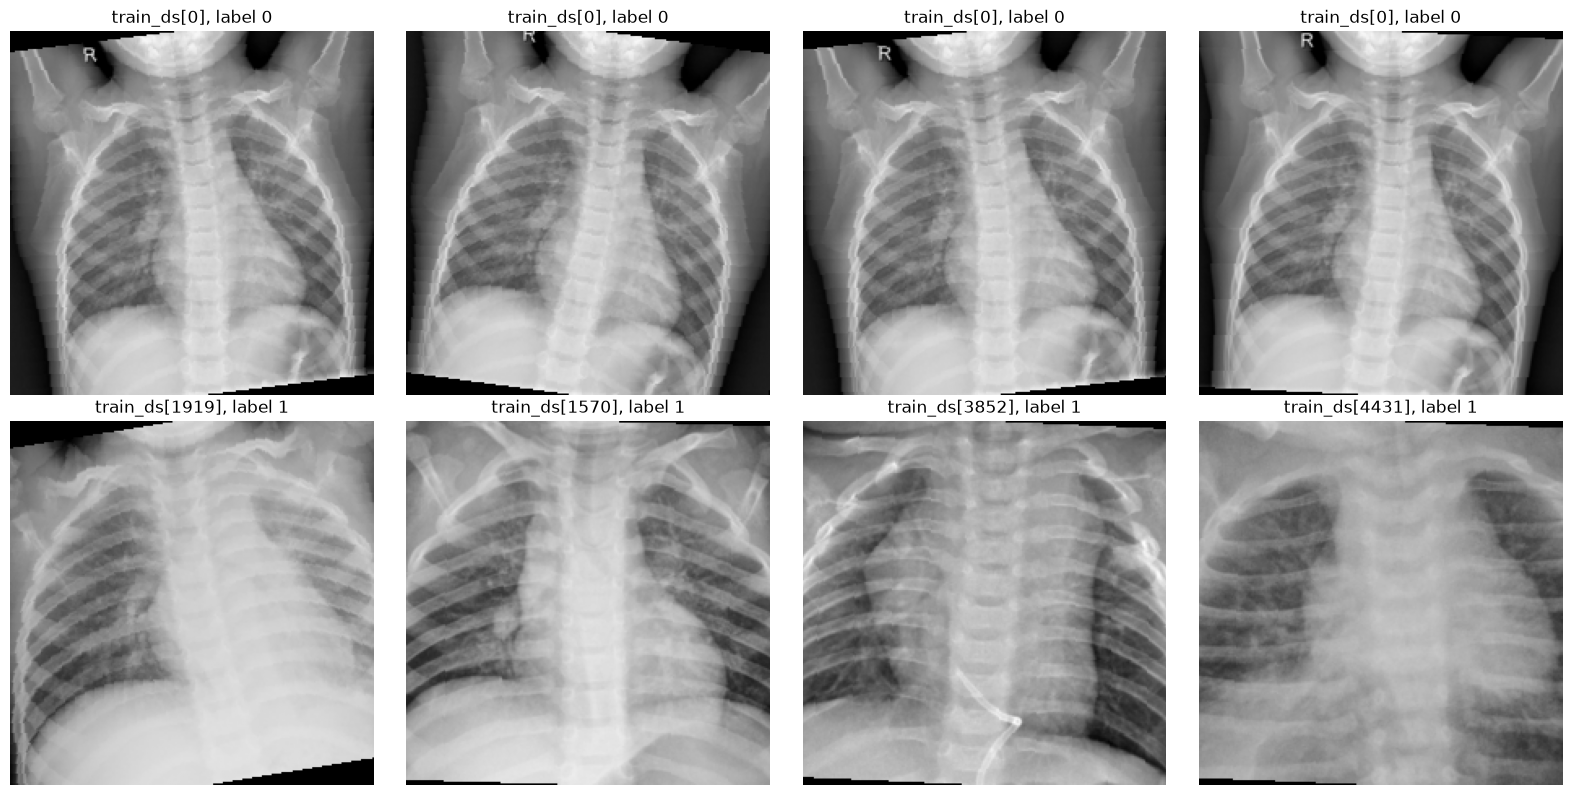

In [85]:
mean_t = torch.tensor(mean).view(3, 1, 1)   # (3,) -> (3, 1, 1) so it lines up with (3, 224, 224)
std_t  = torch.tensor(std).view(3, 1, 1)

def unnormalize(x):
    return x * std_t + mean_t

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# top row: the SAME image 4 times -> 4 different random tilts
for i in range(4):
    x, y = train_ds[0]                       # each call runs train_tf again
    img = unnormalize(x)
    axes[0, i].imshow(img[0], cmap="gray", vmin=0, vmax=1)   # channel 0: all 3 are the same gray
    axes[0, i].set_title(f"train_ds[0], label {y}")
    axes[0, i].axis("off")

# bottom row: 4 DIFFERENT images
rs = random.sample(range(len(train_ds)), 4)
for i in range(4):
    x, y = train_ds[rs[i]]                      
    img = unnormalize(x)
    axes[1, i].imshow(img[0], cmap="gray", vmin=0, vmax=1)   # channel 0: all 3 are the same gray
    axes[1, i].set_title(f"train_ds[{rs[i]}], label {y}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### RESNET 18 from scratch

In [86]:
torch.manual_seed(7053)

model_rs = resnet18(weights=None)        # same architecture as ImageNet ResNet-18, random weights
model_rs.fc = nn.Linear(512, 2)          # (512 in, 2 out)
model_rs = model_rs.to(device)

print(sum(p.numel() for p in model_rs.parameters()))   # about 11.2 million

train(model_rs, path="checkpoints/resnet_scratch.pt", drop=10, epochs=15)

11177538
epoch  1  train loss 0.2946  val loss 0.2661  val acc 0.922 *
epoch  2  train loss 0.1334  val loss 0.1722  val acc 0.950 *
epoch  3  train loss 0.1238  val loss 0.1060  val acc 0.953 *
epoch  4  train loss 0.0957  val loss 0.0977  val acc 0.963 *
epoch  5  train loss 0.0819  val loss 0.1130  val acc 0.961 
epoch  6  train loss 0.0776  val loss 0.0910  val acc 0.969 *
epoch  7  train loss 0.0618  val loss 0.1038  val acc 0.961 
epoch  8  train loss 0.0530  val loss 0.0856  val acc 0.970 *
epoch  9  train loss 0.0533  val loss 0.1422  val acc 0.955 
epoch 10  train loss 0.0513  val loss 0.2286  val acc 0.947 
epoch 11  train loss 0.0348  val loss 0.0902  val acc 0.969 
epoch 12  train loss 0.0246  val loss 0.0867  val acc 0.968 
epoch 13  train loss 0.0216  val loss 0.0818  val acc 0.972 *
epoch 14  train loss 0.0164  val loss 0.0771  val acc 0.969 *
epoch 15  train loss 0.0185  val loss 0.0848  val acc 0.973 


In [94]:
def report(m, name):
    val_loss, val_acc, probs, labels = evaluate(m, val_loader)

    tp, fp, fn, tn = confusion_counts(probs, labels)
    recall, specificity, precision, f1 = rates(tp, fp, fn, tn)
    auc = roc_auc(probs, labels)

    print(f"{name}")
    print(f"  TP {tp}  FP {fp}  FN {fn}  TN {tn}")
    print(f"  recall {recall:.4f}  specificity {specificity:.4f}  "
          f"precision {precision:.4f}  f1 {f1:.4f}  AUC {auc:.4f}")

    # return a dict so the results can go into one table later
    return {
        "model": name, 
        "recall": recall, 
        "specificity": specificity,
        "precision": precision,
        "auc": auc,
        "f1": f1,
        }

### ResNet-18 pretrained, frozen (only the head trains)

In [89]:
torch.manual_seed(7053)

model_fz = resnet18(weights=ResNet18_Weights.DEFAULT)   # ImageNet weights, not random

# 1. freeze: no gradients, no updates for any existing weight
for p in model_fz.parameters():
    p.requires_grad = False

# 2. AFTER freezing: new head. A new layer trains by default.
model_fz.fc = nn.Linear(512, 2)
model_fz = model_fz.to(device)

# 3. check: only the head should be trainable
trainable = sum(p.numel() for p in model_fz.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model_fz.parameters())
print(trainable, total)          # 1026  11177538

train(model_fz, path="checkpoints/resnet_frozen.pt", drop=10, epochs=15)


1026 11177538
epoch  1  train loss 0.2858  val loss 0.1528  val acc 0.946 *
epoch  2  train loss 0.2140  val loss 0.1609  val acc 0.944 
epoch  3  train loss 0.1988  val loss 0.2390  val acc 0.927 
epoch  4  train loss 0.1615  val loss 0.1486  val acc 0.953 *
epoch  5  train loss 0.2442  val loss 0.1756  val acc 0.949 
epoch  6  train loss 0.1901  val loss 0.1811  val acc 0.947 
epoch  7  train loss 0.2376  val loss 0.2772  val acc 0.933 
epoch  8  train loss 0.1511  val loss 0.1662  val acc 0.953 
epoch  9  train loss 0.1493  val loss 0.1695  val acc 0.951 
epoch 10  train loss 0.1332  val loss 0.1805  val acc 0.942 
epoch 11  train loss 0.1288  val loss 0.1524  val acc 0.951 
epoch 12  train loss 0.1200  val loss 0.1575  val acc 0.950 
epoch 13  train loss 0.1104  val loss 0.1591  val acc 0.953 
epoch 14  train loss 0.1122  val loss 0.1515  val acc 0.949 
epoch 15  train loss 0.1205  val loss 0.1739  val acc 0.949 


### ResNet-18 fine-tuned

In [100]:
torch.manual_seed(7053)

model_ft = resnet18(weights=ResNet18_Weights.DEFAULT)   # ImageNet weights, not random

model_ft.fc = nn.Linear(512, 2)
model_ft = model_ft.to(device)     

train(model_ft, path="checkpoints/resnet_finetuned.pt", lr=0.001, drop=10, epochs=15)


epoch  1  train loss 0.1826  val loss 0.0924  val acc 0.959 *
epoch  2  train loss 0.0689  val loss 0.0674  val acc 0.973 *
epoch  3  train loss 0.0554  val loss 0.0507  val acc 0.983 *
epoch  4  train loss 0.0390  val loss 0.0691  val acc 0.973 
epoch  5  train loss 0.0390  val loss 0.0429  val acc 0.988 *
epoch  6  train loss 0.0292  val loss 0.0503  val acc 0.978 
epoch  7  train loss 0.0219  val loss 0.0452  val acc 0.985 
epoch  8  train loss 0.0164  val loss 0.0476  val acc 0.976 
epoch  9  train loss 0.0133  val loss 0.0525  val acc 0.977 
epoch 10  train loss 0.0119  val loss 0.0461  val acc 0.979 
epoch 11  train loss 0.0116  val loss 0.0441  val acc 0.978 
epoch 12  train loss 0.0092  val loss 0.0451  val acc 0.979 
epoch 13  train loss 0.0093  val loss 0.0443  val acc 0.981 
epoch 14  train loss 0.0085  val loss 0.0386  val acc 0.982 *
epoch 15  train loss 0.0078  val loss 0.0440  val acc 0.981 


In [101]:
results = []
results.append(report(model, "SmallCNN"))
results.append(report(model_rs, "ResNet-18 scratch"))
results.append(report(model_fz, "ResNet-18 frozen"))
results.append(report(model_ft, "ResNet-18 fine-tuned"))
pd.DataFrame(results)

SmallCNN
  TP 554  FP 11  FN 10  TN 204
  recall 0.9823  specificity 0.9488  precision 0.9805  f1 0.9814  AUC 0.9958
ResNet-18 scratch
  TP 552  FP 12  FN 12  TN 203
  recall 0.9787  specificity 0.9442  precision 0.9787  f1 0.9787  AUC 0.9961
ResNet-18 frozen
  TP 544  FP 17  FN 20  TN 198
  recall 0.9645  specificity 0.9209  precision 0.9697  f1 0.9671  AUC 0.9870
ResNet-18 fine-tuned
  TP 555  FP 5  FN 9  TN 210
  recall 0.9840  specificity 0.9767  precision 0.9911  f1 0.9875  AUC 0.9990


,model,recall,specificity,precision,auc,f1
0,SmallCNN,0.982270,0.948837,0.980531,0.995761,0.981399
1,ResNet-18 scratch,0.978723,0.944186,0.978723,0.996124,0.978723
2,ResNet-18 frozen,0.964539,0.920930,0.969697,0.987044,0.967111
3,ResNet-18 fine-tuned,0.984043,0.976744,0.991071,0.999010,0.987544
